In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_eff096_notrueptcons.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [6]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [7]:
print(df_match.shape[0], df_allfake.shape[0])

2412535 1527396


In [8]:
print(np.unique(df_match['bs']))

[-1  1]


In [9]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [10]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [11]:
plt.rcParams['font.size'] = 12

In [ ]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [ ]:
rc_allfake_bs_vs_pts_array

In [15]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [16]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [17]:
b_fake_array

[array([0.61740038, 0.38259962]),
 array([0.61124816, 0.38875184]),
 array([0.60139586, 0.39860414]),
 array([0.59627859, 0.40372141]),
 array([0.59576909, 0.40423091])]

In [18]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

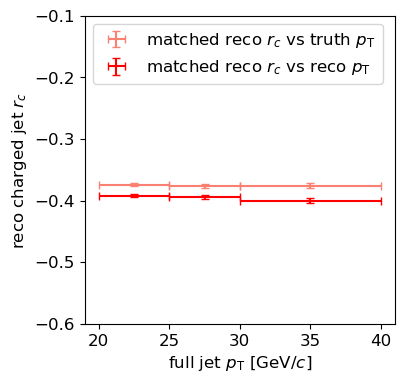

In [20]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [21]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.6973853 0.3026147]
[0.69610824 0.30389176]
[0.69688501 0.30311499]
[0.70002365 0.29997635]
[0.70214896 0.29785104]


In [22]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_608370/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [23]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.31279212, 0.26045882, 0.23336943, 0.21570573, 0.20516954])

$r_c$ correction is not needed

In [24]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

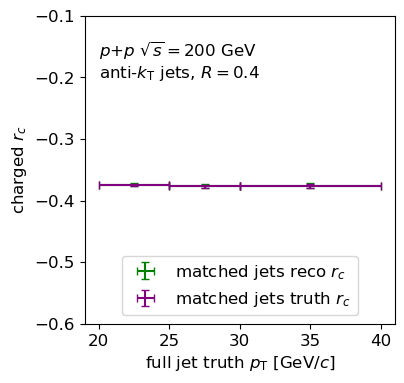

In [25]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='g', ls='none', label='matched jets reco $r_c$')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:-1], capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [26]:
print(sum(df_match[(df_match.bs!=df_match.b)]['w'])/sum(df_match['w']))

0.0008661918078712668


In [27]:
print(sum(df_match[(df_match.bs!=df_match.b)&(df_match.pt>20)&(df_match.pts>15)]['w'])/sum(df_match[(df_match.pt>20)&(df_match.pts>15)]['w']))

0.0014805537713396884


In [28]:
print(rc_match_bs_vs_pt_array)
print(rc_match_b_vs_pt_array)

[-0.39259369189792265, -0.3741508308260349, -0.375992247052907, -0.37567807046602836, -0.3659752334255491]
[-0.3929469875088625, -0.3749042355295432, -0.3769716328705672, -0.37643241325447485, -0.36805873266115496]


Process data

In [29]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [30]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [31]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [32]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [33]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [34]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [35]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[237769.79552279 116457.00327054]
[487.61644304 341.25797173]
1
[72379. 38554.]
[54717.91476223 27321.60734076]
[233.91860713 165.29249027]
2
[16450.  8688.]
[12921.94683155  6349.61246127]
[113.6747414   79.68445558]
3
[4758. 2573.]
[3815.08160694 1934.57971005]
[61.76634688 43.98385738]
4
[334. 153.]
[274.4722011  112.61023074]
[16.56720257 10.61179677]


In [36]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

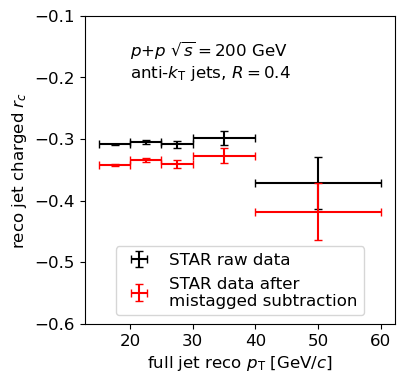

In [37]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [38]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [39]:
reweight_array

[array([0.96250386, 1.08641107]),
 array([0.95814148, 1.09588303]),
 array([0.96216592, 1.08698349]),
 array([0.94787017, 1.12164998]),
 array([1.00987041, 0.97673167])]

([], [])

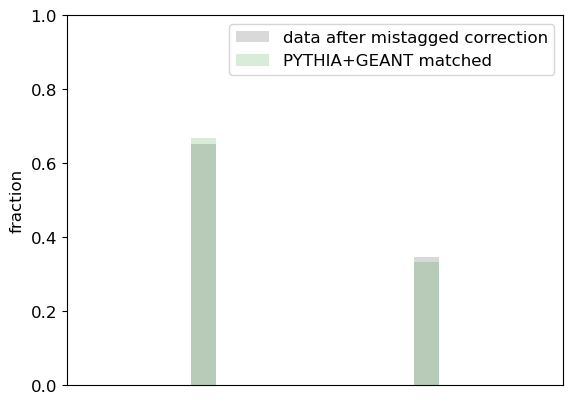

In [40]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [41]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.746029305931756
anomaly reco pT: 65.45530859825888
anomaly reco pT: 63.085829497123754
anomaly reco pT: 66.83963074901102
anomaly reco pT: 62.38132748663066
anomaly reco pT: 62.99359031776366
anomaly reco pT: 67.1333301990355
anomaly reco pT: 63.64818004148316
anomaly reco pT: 60.55736397596093
anomaly reco pT: 64.06767594033505
anomaly reco pT: 6

anomaly reco pT: 60.396526050380544
anomaly reco pT: 61.08133864736215
anomaly reco pT: 60.71513640529403
anomaly reco pT: 63.08584362374407
anomaly reco pT: 68.24831923111424
anomaly reco pT: 62.8181597276261
anomaly reco pT: 61.412439493673766
anomaly reco pT: 61.347736871062985
anomaly reco pT: 61.02147632892541
anomaly reco pT: 70.03649149954671
anomaly reco pT: 60.757687655694376
anomaly reco pT: 66.22961059676287
anomaly reco pT: 60.293464781197066
anomaly reco pT: 60.25965231087885
anomaly reco pT: 60.69135212323932
anomaly reco pT: 60.11974178663405
anomaly reco pT: 62.372927580141585
anomaly reco pT: 60.47297117299494
anomaly reco pT: 60.87052921361896
anomaly reco pT: 65.37212921820844
anomaly reco pT: 63.85124183763149
anomaly reco pT: 63.759893817755874
anomaly reco pT: 63.188745780398214
anomaly reco pT: 62.99263000665732
anomaly reco pT: 62.0405152806232
anomaly reco pT: 63.85868332105672
anomaly reco pT: 60.84893399987448
anomaly reco pT: 60.307286378938315
anomaly reco 

anomaly reco pT: 65.86804145154221
anomaly reco pT: 60.039992416227214
anomaly reco pT: 60.217385119456345
anomaly reco pT: 61.23079662193888
anomaly reco pT: 62.296368200663885
anomaly reco pT: 60.58564821822483
anomaly reco pT: 61.68059794731317
anomaly reco pT: 62.832636315781265
anomaly reco pT: 63.82654613577097
anomaly reco pT: 69.078424585103
anomaly reco pT: 64.21149177204236
anomaly reco pT: 65.37225443338379
anomaly reco pT: 62.139763620120824
anomaly reco pT: 61.798087886220436
anomaly reco pT: 60.48160954995578
anomaly reco pT: 67.18709477662233
anomaly reco pT: 60.09020994455192
anomaly reco pT: 61.619524213622306
anomaly reco pT: 63.31898904982115
anomaly reco pT: 60.07102500643125
anomaly reco pT: 62.08195655168501
anomaly reco pT: 63.149861630056094
anomaly reco pT: 67.71156900536265
anomaly reco pT: 64.46056243711806
anomaly reco pT: 60.343003086835424
anomaly reco pT: 65.91601498024252
anomaly reco pT: 60.027108758120775
anomaly reco pT: 62.58741574557798
anomaly reco

anomaly reco pT: 70.64250379062159
anomaly reco pT: 62.912793080628866
anomaly reco pT: 62.62036063826332
anomaly reco pT: 61.10476487708871
anomaly reco pT: 60.50659974179755
anomaly reco pT: 66.94727996267524
anomaly reco pT: 73.39946693221643
anomaly reco pT: 61.22578698730328
anomaly reco pT: 61.29062756689943
anomaly reco pT: 62.553255622557934
anomaly reco pT: 61.930048604173756
anomaly reco pT: 61.38677872346441
anomaly reco pT: 63.47305061763001
anomaly reco pT: 61.641088226629975
anomaly reco pT: 61.77018429862436
anomaly reco pT: 60.57106435333869
anomaly reco pT: 62.5219345419139
anomaly reco pT: 60.61298014218606
anomaly reco pT: 65.14922986425985
anomaly reco pT: 63.23640606330383
anomaly reco pT: 62.45668089267042
anomaly reco pT: 65.2417758455668
anomaly reco pT: 61.87965229933331
anomaly reco pT: 65.78375002024931
anomaly reco pT: 71.94586521378704
anomaly reco pT: 62.09564203628626
anomaly reco pT: 62.80039432437575
anomaly reco pT: 64.02756716164482
anomaly reco pT: 6

anomaly reco pT: 63.44584168696167
anomaly reco pT: 60.05724498304847
anomaly reco pT: 64.93741492529657
anomaly reco pT: 60.81330520834206
anomaly reco pT: 61.7961645052885
anomaly reco pT: 65.71729226850006
anomaly reco pT: 69.76373465662891
anomaly reco pT: 63.743163597286255
anomaly reco pT: 61.79103685180874
anomaly reco pT: 65.60260368695586
anomaly reco pT: 60.53151935897834
anomaly reco pT: 62.99651256623422
anomaly reco pT: 62.819668811200835
anomaly reco pT: 61.452905582931486
anomaly reco pT: 62.321086893556085
anomaly reco pT: 60.41934591709344
anomaly reco pT: 70.4948930673022
anomaly reco pT: 60.49672036084959
anomaly reco pT: 60.51323384205352
anomaly reco pT: 62.48610477267892
anomaly reco pT: 60.56858657297721
anomaly reco pT: 65.26794459022335
anomaly reco pT: 65.63303061561845
anomaly reco pT: 60.00616454773063
anomaly reco pT: 61.05501541986944
anomaly reco pT: 60.169177830287424
anomaly reco pT: 60.57780474950716
anomaly reco pT: 65.2570259002253
anomaly reco pT: 6

anomaly reco pT: 62.99505969229138
anomaly reco pT: 60.723222920459904
anomaly reco pT: 71.01868458502177
anomaly reco pT: 61.027749387158586
anomaly reco pT: 60.267100761302615
anomaly reco pT: 66.44668233355917
anomaly reco pT: 60.260942601705516
anomaly reco pT: 70.86250121653538
anomaly reco pT: 65.87964645176156
anomaly reco pT: 61.79199957702336
anomaly reco pT: 60.80116072274952
anomaly reco pT: 61.29109086638426
anomaly reco pT: 63.530619029638
anomaly reco pT: 63.32693347301722
anomaly reco pT: 61.60132182648758
anomaly reco pT: 60.13131655026961
anomaly reco pT: 62.00787728817603
anomaly reco pT: 60.46832888935439
anomaly reco pT: 64.24219053076585
anomaly reco pT: 66.53335359223479
anomaly reco pT: 61.77520138171616
anomaly reco pT: 61.42742862801765
anomaly reco pT: 61.93806738893992
anomaly reco pT: 60.43602258426345
anomaly reco pT: 60.49366028427507
anomaly reco pT: 66.69510962471013
anomaly reco pT: 60.739472612887816
anomaly reco pT: 65.71858244372748
anomaly reco pT: 

... (35 outputs left out)

anomaly reco pT: 61.43344668901912
anomaly reco pT: 61.66225662840047
anomaly reco pT: 60.60958724554956
anomaly reco pT: 60.31704199840467
anomaly reco pT: 67.4646051558249
anomaly reco pT: 67.64244708056327
anomaly reco pT: 63.51448076044319
anomaly reco pT: 63.660082068363224
anomaly reco pT: 60.84198874402022
anomaly reco pT: 60.4587879171776
anomaly reco pT: 60.560392574699236
anomaly reco pT: 62.164487199327795
anomaly reco pT: 63.13238709698934
anomaly reco pT: 64.90706979256086
anomaly reco pT: 66.87511769271656
anomaly reco pT: 62.7743493979457
anomaly reco pT: 61.00917409332218
anomaly reco pT: 61.54162745871625
anomaly reco pT: 62.98309924002085
anomaly reco pT: 61.69092781775847
anomaly reco pT: 61.20278902517118
anomaly reco pT: 62.50164603854626
anomaly reco pT: 61.622378315956055
anomaly reco pT: 63.111860948037666
anomaly reco pT: 70.3342361412224
anomaly reco pT: 63.3812053858002
anomaly reco pT: 60.322275850229055
anomaly reco pT: 70.93000314615792
anomaly reco pT: 61

anomaly reco pT: 64.62206824734714
anomaly reco pT: 60.46656574446182
anomaly reco pT: 61.285313715124275
anomaly reco pT: 61.330350980727744
anomaly reco pT: 64.19548711153159
anomaly reco pT: 63.60277263479115
anomaly reco pT: 60.88958171186299
anomaly reco pT: 66.7452749265485
anomaly reco pT: 62.86293580355628
anomaly reco pT: 62.74325096655931
anomaly reco pT: 60.26905338747298
anomaly reco pT: 62.97918714158118
anomaly reco pT: 63.34239460532443
anomaly reco pT: 60.8607816268325
anomaly reco pT: 60.13939267986104
anomaly reco pT: 61.75612617447483
anomaly reco pT: 64.28017962734752
anomaly reco pT: 60.45550057153907
anomaly reco pT: 67.13651829633228
anomaly reco pT: 61.971956429237736
anomaly reco pT: 60.09400497968536
anomaly reco pT: 64.6719463333965
anomaly reco pT: 62.55747031202144
anomaly reco pT: 66.19232654409319
anomaly reco pT: 60.34762963500487
anomaly reco pT: 68.35192186330552
anomaly reco pT: 61.73787515147687
anomaly reco pT: 66.90810574089258
anomaly reco pT: 61.

anomaly reco pT: 61.82668124871424
anomaly reco pT: 60.21708012672239
anomaly reco pT: 63.192743123542
anomaly reco pT: 73.30579875773192
anomaly reco pT: 71.55137974550456
anomaly reco pT: 74.06006953258527
anomaly reco pT: 63.80994630821136
anomaly reco pT: 63.459838901560616
anomaly reco pT: 61.06207397807897
anomaly reco pT: 60.117810075867474
anomaly reco pT: 60.634503322289035
anomaly reco pT: 71.76348785792916
anomaly reco pT: 65.75536078835533
anomaly reco pT: 62.09348684245564
anomaly reco pT: 65.12492060824782
anomaly reco pT: 60.21862550922213
anomaly reco pT: 68.36080273136002
anomaly reco pT: 61.178726833300146
anomaly reco pT: 60.070878682848516
anomaly reco pT: 65.10737055182676
anomaly reco pT: 60.65170514910797


/tmp/ipykernel_608370/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [42]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [43]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [44]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

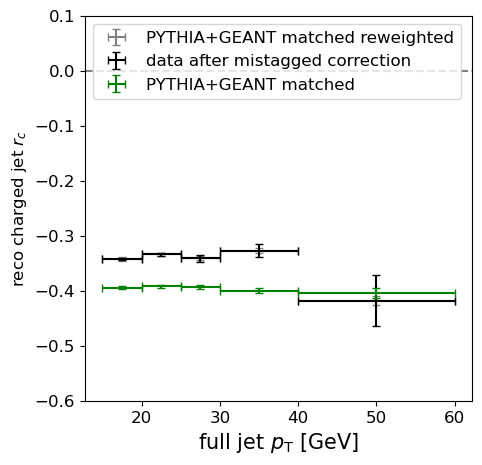

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [46]:
print(rc_match_bs_vs_pts_array_rw)

[-0.342472090383049, -0.333940358492987, -0.3410380172402175, -0.32706307262411416, -0.41815891668430666]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

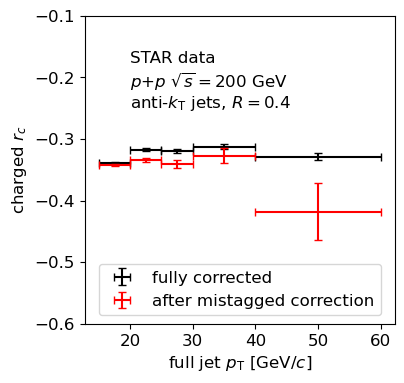

In [47]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

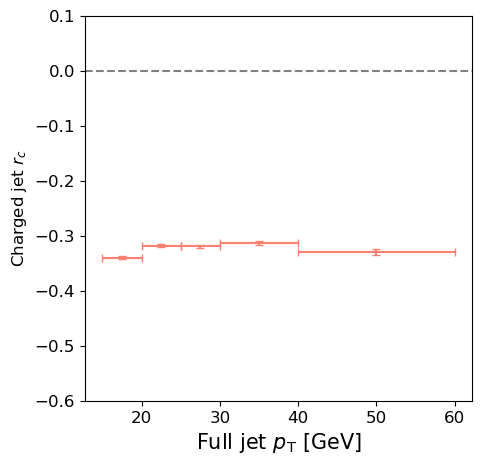

In [48]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [49]:
rc_match_bs_vs_pt_array

[-0.3397440286771071,
 -0.3177809201140156,
 -0.31913066376445315,
 -0.3125725138283411,
 -0.3291196234905398]

In [50]:
rc_err_match_bs_vs_pt_array

[0.0028468040472893388,
 0.00237298277722111,
 0.002934510314089952,
 0.0036521819173666514,
 0.005477003451151029]